In [1]:
import pandas as pd
import seaborn as sns
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [4]:
candy = pd.read_csv('candy.csv', index_col=0)
candy.head()

,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
competitorname,,,,,,,,,,,,
100 Grand,1,0,1,0,0,1,0,1,0,0.732,0.860,66.971725
3 Musketeers,1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936
One dime,0,0,0,0,0,0,0,0,0,0.011,0.116,32.261086
One quarter,0,0,0,0,0,0,0,0,0,0.011,0.511,46.116505
Air Heads,0,1,0,0,0,0,0,0,0,0.906,0.511,52.341465


In [5]:
candy.shape # (rows, columns)

(85, 12)

In [6]:
candy = candy.drop_duplicates()
candy = candy.dropna()
candy.shape

(85, 12)

In [7]:
candy.describe().T

,count,mean,std,min,25%,50%,75%,max
chocolate,85.0,0.435294,0.498738,0.000000,0.000000,0.000000,1.000000,1.00000
fruity,85.0,0.447059,0.500140,0.000000,0.000000,0.000000,1.000000,1.00000
caramel,85.0,0.164706,0.373116,0.000000,0.000000,0.000000,0.000000,1.00000
peanutyalmondy,85.0,0.164706,0.373116,0.000000,0.000000,0.000000,0.000000,1.00000
nougat,85.0,0.082353,0.276533,0.000000,0.000000,0.000000,0.000000,1.00000
crispedricewafer,85.0,0.082353,0.276533,0.000000,0.000000,0.000000,0.000000,1.00000
hard,85.0,0.176471,0.383482,0.000000,0.000000,0.000000,0.000000,1.00000
bar,85.0,0.247059,0.433861,0.000000,0.000000,0.000000,0.000000,1.00000
pluribus,85.0,0.517647,0.502654,0.000000,0.000000,1.000000,1.000000,1.00000
sugarpercent,85.0,0.478647,0.282778,0.011000,0.220000,0.465000,0.732000,0.98800


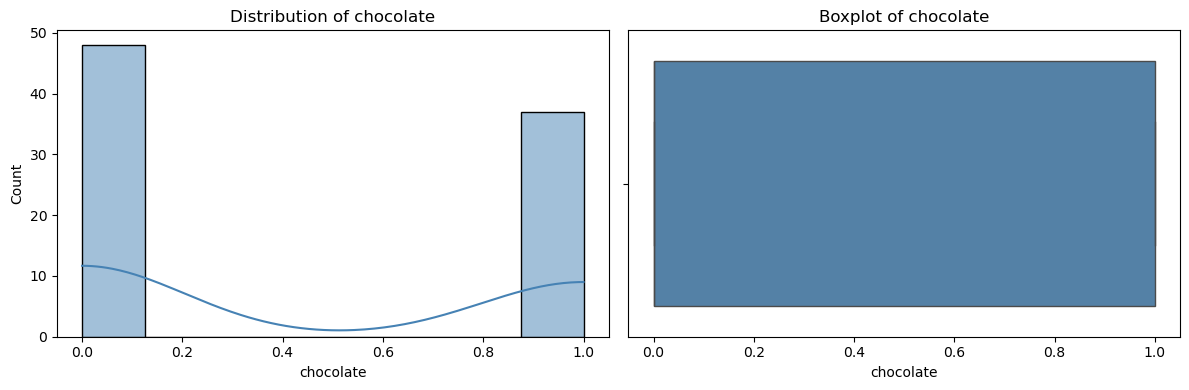

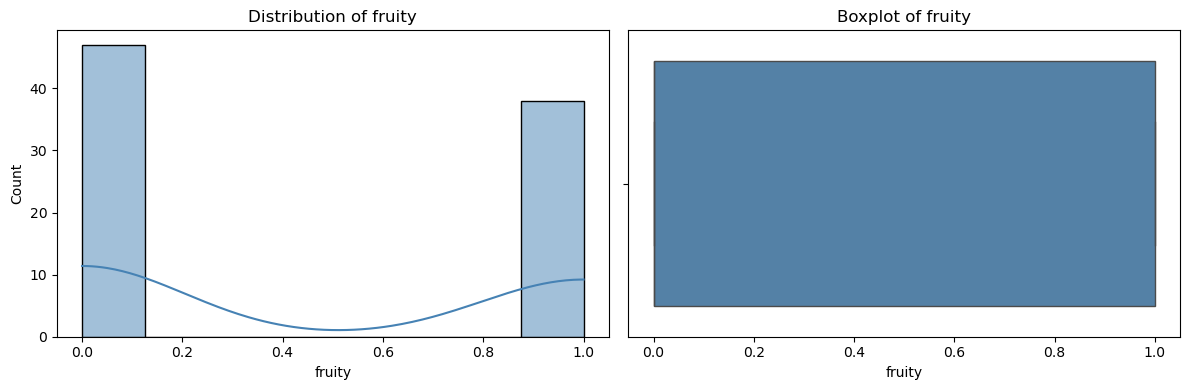

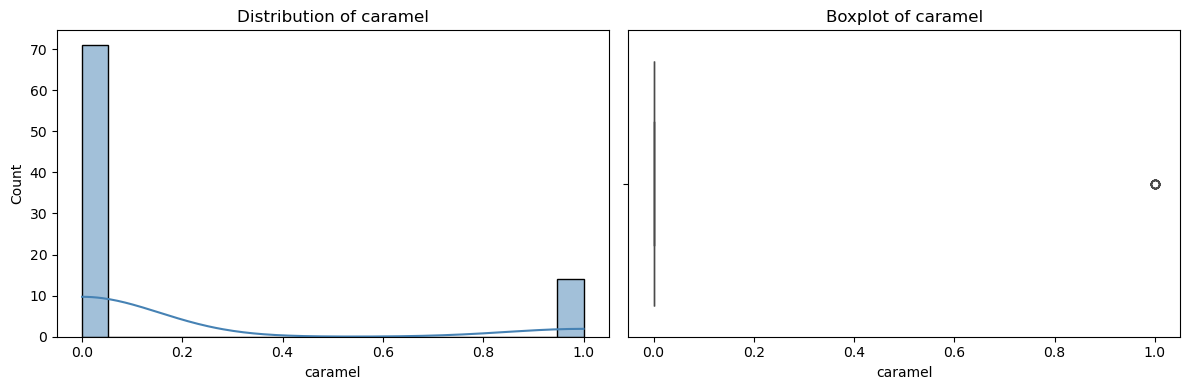

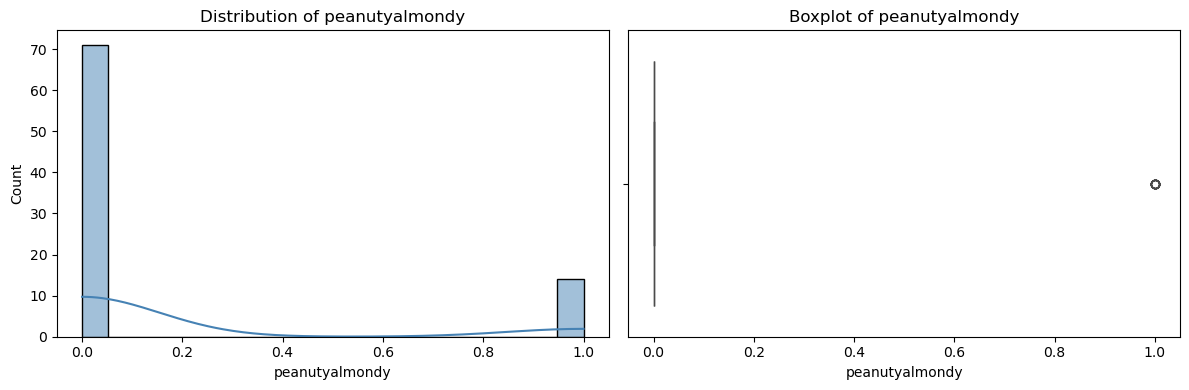

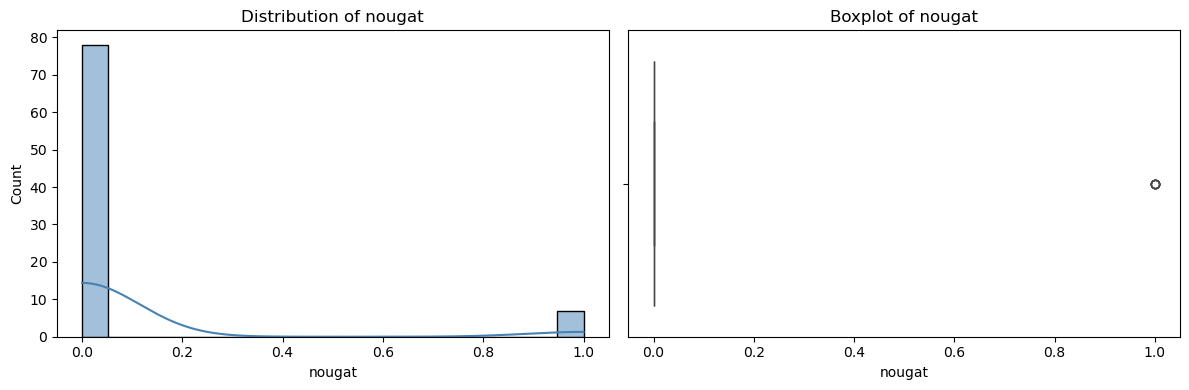

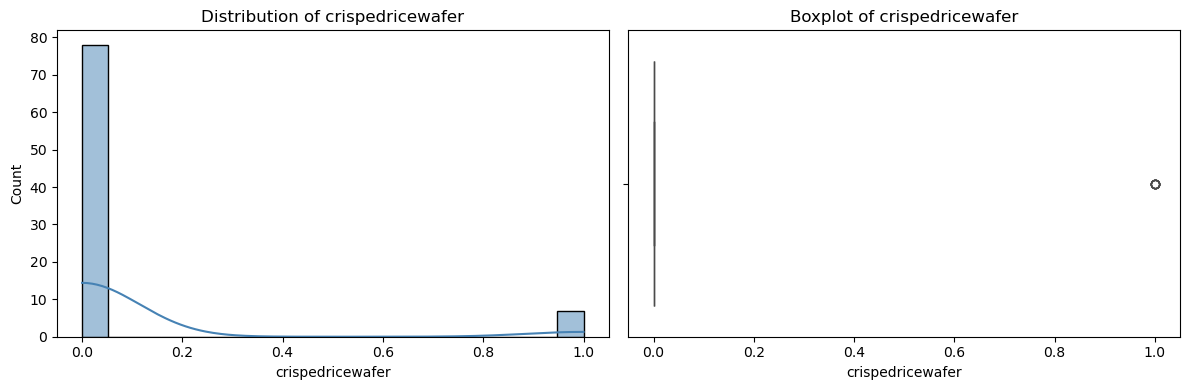

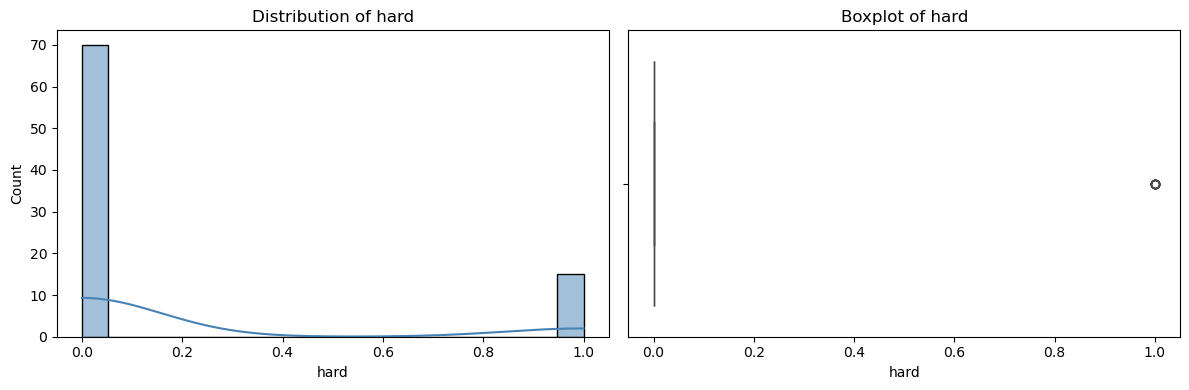

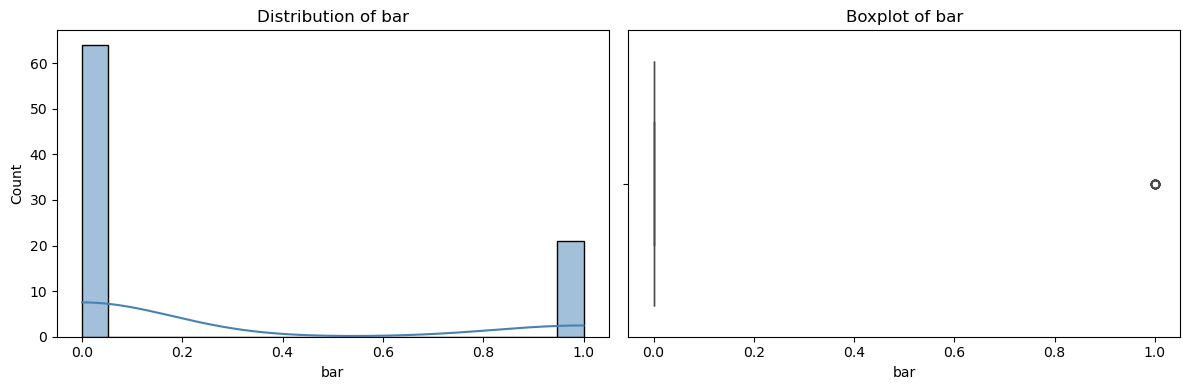

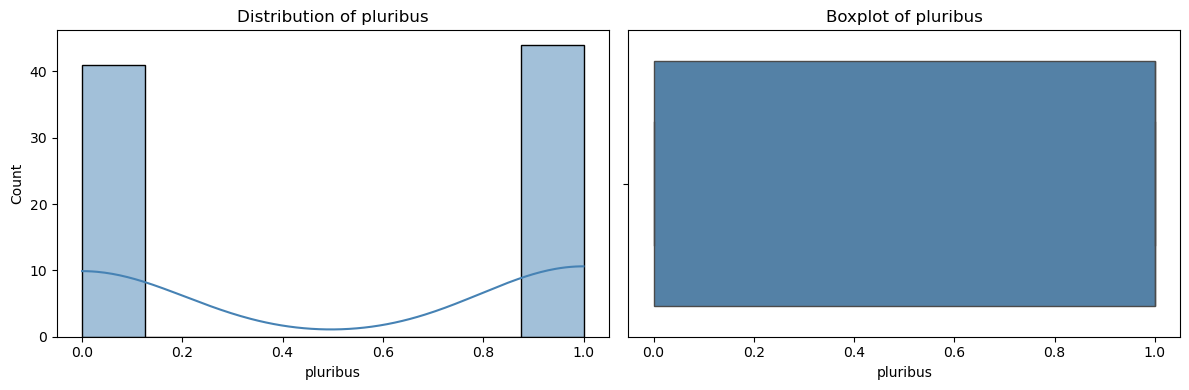

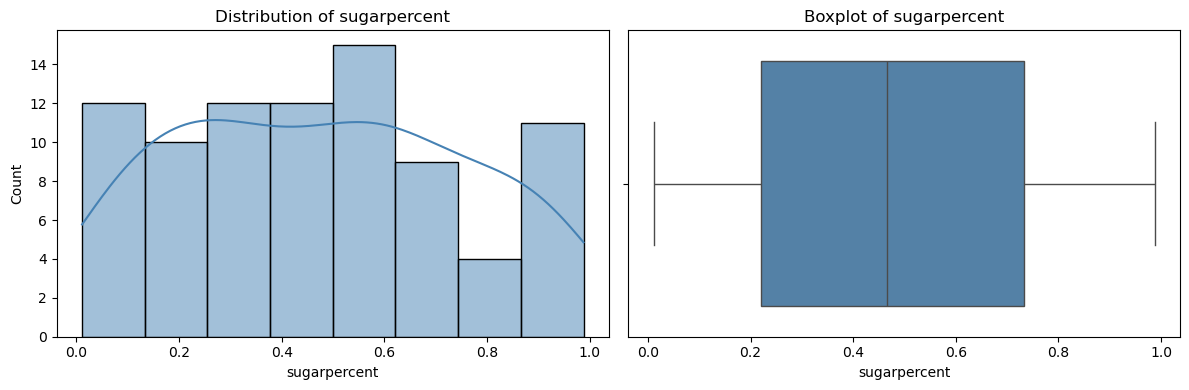

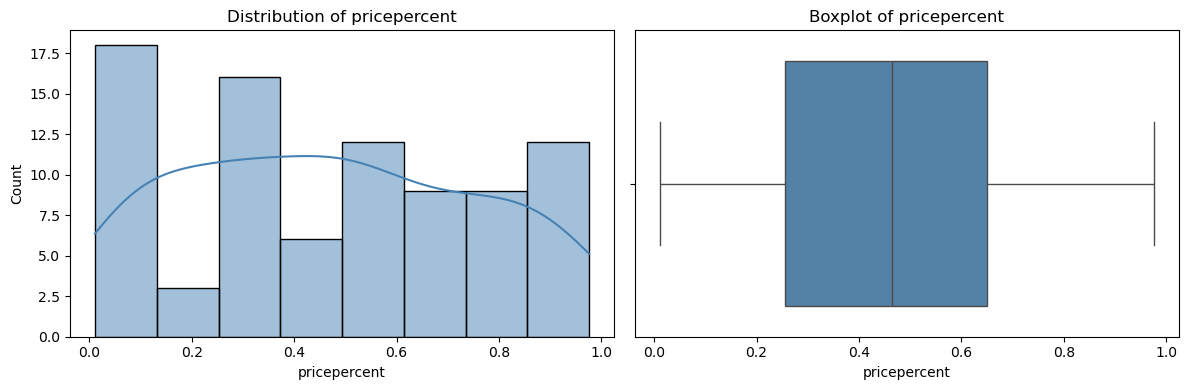

In [8]:
numerical_cols = candy.columns.drop('winpercent')

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(candy[col], kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(x=candy[col], ax=axes[1], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [9]:
target_col = "winpercent"
drop_cols = [c for c in ["id", "competitorname", target_col] if c in candy.columns]
X = candy.drop(columns=drop_cols)
y = candy[target_col]
# 3. Train / validation split
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

In [10]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(1),  # Linear output for regression
])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 192 (768.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="mae",      # Mean Absolute Error (in winpercent points)
    metrics=["mae"],
)

In [14]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    min_delta=0.01,
    restore_best_weights=True,
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=16,
    epochs=300,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - loss: 49.7312 - mae: 49.7312 - val_loss: 51.9503 - val_mae: 51.9503
Epoch 2/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 49.6188 - mae: 49.6188 - val_loss: 51.9827 - val_mae: 51.9827
Epoch 3/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 49.5658 - mae: 49.5658 - val_loss: 52.0111 - val_mae: 52.0111
Epoch 4/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 49.6224 - mae: 49.6224 - val_loss: 52.0213 - val_mae: 52.0213
Epoch 5/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 49.5032 - mae: 49.5032 - val_loss: 52.0470 - val_mae: 52.0470
Epoch 6/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 49.6099 - mae: 49.6099 - val_loss: 52.0567 - val_mae: 52.0567
Epoch 7/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 49.4256 - mae: 49.4256 - val_loss: 52.0833 - val_mae: 52.0833
Epoch 8/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 49.4514 - mae: 49.4514 - val_loss: 52.1001 - val_mae: 52.1001
Epoch 9/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 

Best Validation Loss: 51.9503
Best Validation Accuracy: 52.1165
Validation MAE: 51.95

--- Sample Predictions ---
Actual: 47.17 | Predicted: 0.66 | Diff: 46.52
Actual: 66.97 | Predicted: 1.01 | Diff: 65.96
Actual: 67.04 | Predicted: 0.74 | Diff: 66.29
Actual: 55.38 | Predicted: 0.26 | Diff: 55.11
Actual: 24.52 | Predicted: 0.84 | Diff: 23.69


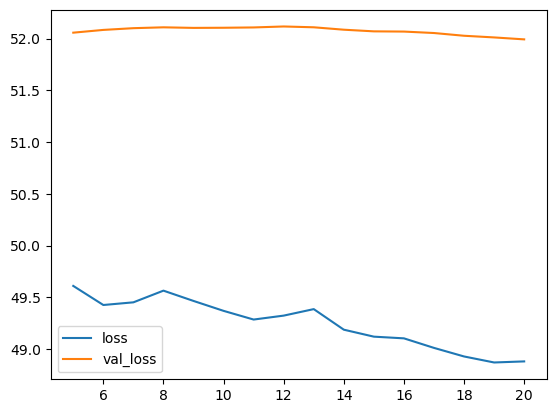

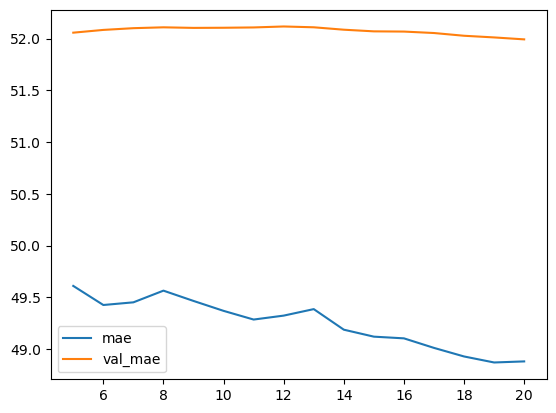

In [23]:
history_df = pd.DataFrame(history.history)
# Start the plot at epoch 5
history_df.loc[5:, ['loss', 'val_loss']].plot()
history_df.loc[5:, ['mae', 'val_mae']].plot()

print(("Best Validation Loss: {:0.4f}" +\
      "\nBest Validation Accuracy: {:0.4f}")\
      .format(history_df['val_loss'].min(), 
              history_df['val_mae'].max()))
print(f"Validation MAE: {val_mae:.2f}")
print("\n--- Sample Predictions ---")
for actual, pred in zip(y_valid[:5], preds.flatten()):
    print(
        f"Actual: {actual:,.2f} | Predicted: {pred:,.2f} | Diff:"
        f" {abs(actual - pred):,.2f}"
    )